Importing Libraries

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize

In [27]:
@jit(nopython=True)
def Pressure(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def chemical_potential(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def energy_density(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

constructing EoS :

In [51]:
# Initial Values :

n_had =np.linspace(0.16,0.32,1000)
Gam_had = 4.921
K_had = 17906.60
m0_had = 939.56

pressure_transition = 63.177
energy_density_transition = 318.26
energy_density_transition_jump = 253.89
energy_density_quark = energy_density_transition + energy_density_transition_jump

n_quark = np.linspace(0.5344,2,1000)
Gam_quark = 2.5
K_quark = pressure_transition / (n_quark[0] ** Gam_quark)
m0_quark = (energy_density_quark - (K_quark * (n_quark[0] ** Gam_quark)) / (Gam_quark - 1)) / n_quark[0]

n_total = np.linspace(0.16,2,2000)

EoS Hadronic

In [52]:
pressure_had = Pressure(n_total, K_had, Gam_had)
chemical_potential_had = chemical_potential(n_total, K_had, Gam_had, m0_had)
energy_density_had = energy_density(n_total, K_had, Gam_had, m0_had)

EoS Quark

In [53]:
pressure_quark = Pressure(n_total, K_quark, Gam_quark)
chemical_potential_quark = chemical_potential(n_total, K_quark, Gam_quark, m0_quark)
energy_density_quark = energy_density(n_total, K_quark, Gam_quark, m0_quark)

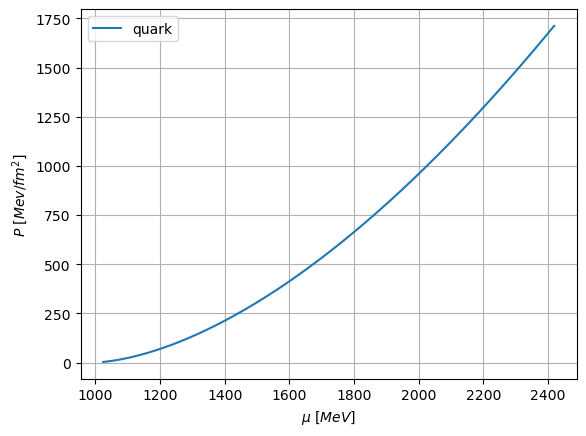

In [54]:
#plt.plot(chemical_potential_had, pressure_had, label = "hadronic")
plt.plot(chemical_potential_quark,pressure_quark, label = "quark")

#plt.xlim([950,1400])
#plt.ylim([0,200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [55]:
mu_quark_new = []
for i in range(100):
    mu_quark_0 = (chemical_potential_quark - 50 + i)
    mu_quark_new.append(mu_quark_0)

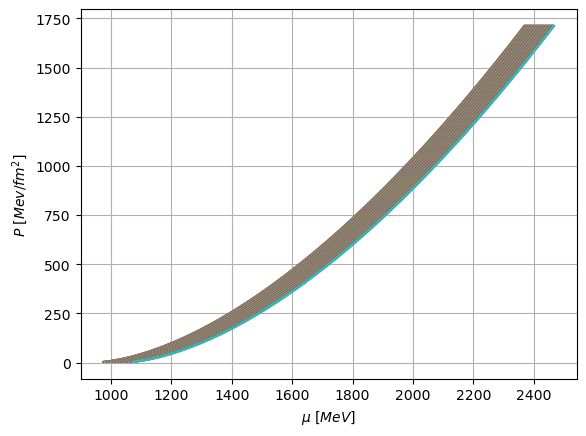

In [56]:
for i in range(len(mu_quark_new)):  # Assuming mu_quark_new is a list of lists
    plt.plot(mu_quark_new[i], pressure_quark, label=f"quark set {i+1}")

#plt.plot(chemical_potential_had, pressure_had, label="hadronic", color='black', linewidth=2)  # Hadronic plot
#plt.xlim([950, 1400])
#plt.ylim([0, 200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
#plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1))  # Adjust legend position to handle many labels
plt.grid()
plt.show()

In [57]:
mu_quark_set

array([1073.10546083, 1073.23270687, 1073.36011969, ..., 1544.55181675,
       1544.86962302, 1545.1874961 ])

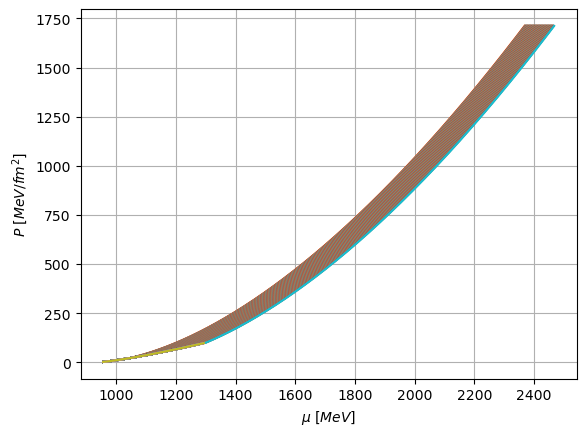

In [58]:
x1 = np.array(chemical_potential_had)
y1 = np.array(pressure_had)

# Interpolate the hadronic phase data
P_h_int_func = interpolate.interp1d(x1, y1)

# List to store combined curves for each quark phase
combined_mu_curves_quark, combined_mu_curves_had = [], []
combined_P_curves_quark, combined_P_curves_had = [], []
P_crit = []
mu_crit = []

combined_mu_curves, combined_p_curves = [], []
index_points =[]

# Loop over all the mu_quark sets in mu_quark_new
for i, mu_quark_set in enumerate(mu_quark_new):
    x2 = np.array(mu_quark_set)
    y2 = np.array(pressure_quark)  # Assuming P_3_all is the same for all quark sets

    # Generate a new mu array for interpolation
    mu_new = np.linspace(min(mu_quark_set), max(mu_quark_set), 1000)
    P_had_array = P_h_int_func(mu_new)

    # Interpolate quark phase data
    P_q_int_func = interpolate.interp1d(x2, y2)
    P_quark_array = P_q_int_func(mu_new)

    # Calculate the difference between hadronic and quark phases
    y_diff = np.abs(P_had_array - P_quark_array)
    index_intersect = np.argmin(y_diff)  # Approximate intersection index in the interpolated array

    # Get the approximate intersection point
    x_intersect = mu_new[index_intersect]

    # Find the closest index in the original arrays to this intersection point
    index_had_closest = (np.abs(x1 - x_intersect)).argmin()
    index_quark_closest = (np.abs(x2 - x_intersect)).argmin()

    index_points.append(index_had_closest)

    # Slice the original arrays at the closest intersection points
    mu_had_1 = x1[:index_had_closest]
    P_had = y1[:index_had_closest]
    mu_quark_2 = x2[index_quark_closest:]
    P_quark_2 = y2[index_quark_closest:]

    P_crit.append(P_quark_2[0])
    mu_crit.append(mu_quark_2[0])

    # Combine the original arrays at the intersection point
    combined_mu = np.concatenate((mu_had_1, mu_quark_2))
    combined_P = np.concatenate((P_had, P_quark_2))

    combined_mu_curves.append(combined_mu)
    combined_p_curves.append(combined_P)

    # Store the combined curves in the list
    combined_mu_curves_quark.append(mu_quark_2)
    combined_P_curves_quark.append(P_quark_2)

    # Store the combined curves in the list
    combined_mu_curves_had.append(mu_had_1)
    combined_P_curves_had.append(P_had)

# Plot the combined curves
for i in range(len(combined_mu_curves_had)):
    plt.plot(combined_mu_curves_had[i], combined_P_curves_had[i], label=f"Combined Curve {i+1}")
    plt.plot(combined_mu_curves_quark[i], combined_P_curves_quark[i], label=f"Combined Curve {i+1}")

# Final plot settings
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [MeV/fm^2]$")
# plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1))  # Uncomment if legend is needed
plt.grid()
plt.show()


In [59]:
def gradient(n, m):
    
    if len(n) != len(m):
        raise ValueError("n and m must have the same length.")
    
    gradients = []
    for i in range(len(n) - 1):  # Loop up to the second-to-last element
        grad = (n[i + 1] - n[i]) / (m[i + 1] - m[i])
        gradients.append(grad)
    
    return gradients

In [60]:
combined_n = []
combined_e = []
combined_cs2 = []
combined_p_1, combined_mu_1 = [], []
combined_cs2_11 = []
# Loop over each combined curve to calculate the gradient
for i in range(len(combined_P_curves_had)):
    P_curve_1 = combined_P_curves_had[i]
    mu_curve_1 = combined_mu_curves_had[i]

    P_curve_2 = combined_P_curves_quark[i]
    mu_curve_2 = combined_mu_curves_quark[i]

    # Compute the gradient of P with respect to mu
    gradient_1 = np.gradient(P_curve_1, mu_curve_1)
    gradient_2 = np.gradient(P_curve_2, mu_curve_2)

    e_curve_1 = (gradient_1*mu_curve_1)-P_curve_1
    cs2_1 = np.gradient(P_curve_1,e_curve_1)

    e_curve_2 = (gradient_2*mu_curve_2)-P_curve_2
    cs2_2 = np.gradient(P_curve_2,e_curve_2)

    P_curve_22 = np.linspace(P_curve_1[-1],P_curve_1[-1],10)
    mu_curve_22 = np.linspace(mu_curve_1[-1],mu_curve_1[-1],10)
    e_curve_22 = np.linspace(e_curve_1[-1],e_curve_2[0],10)
    cs2_22 = np.gradient(P_curve_22,e_curve_22)

    combined_n.append(np.concatenate((gradient_1,gradient_2)))
    combined_e.append(np.concatenate((e_curve_1,e_curve_22,e_curve_2)))
    combined_cs2.append(np.concatenate((cs2_1,cs2_22,cs2_2)))
    combined_p_1.append(np.concatenate((P_curve_1,P_curve_22,P_curve_2)))
    combined_mu_1.append(np.concatenate((mu_curve_1,mu_curve_22,mu_curve_2)))


    cs2_11 = np.gradient(np.concatenate((P_curve_1,P_curve_22,P_curve_2)),np.concatenate((e_curve_1,e_curve_22,e_curve_2)))
    combined_cs2_11.append(cs2_11)


In [216]:
combined_n = []
combined_e = []
combined_cs2 = []
combined_p_1, combined_mu_1 = [], []

# Loop over each combined curve to calculate the gradient
for i in range(len(combined_P_curves_had)):
    P_curve_1 = combined_P_curves_had[i]
    mu_curve_1 = combined_mu_curves_had[i]

    P_curve_2 = combined_P_curves_quark[i]
    mu_curve_2 = combined_mu_curves_quark[i]

    P_11 = np.concatenate((P_curve_1,P_curve_2))
    mu_11 = np.concatenate((mu_curve_1,mu_curve_2))

    gradient_11 = gradient(P_11, mu_11)
    e_11 = (gradient_11*mu_11[:-1])-P_11[:-1]
    combined_cs2.append(gradient(P_11[:-1],e_11))
    combined_n.append(gradient_11)
    combined_e.append(e_11)
    combined_p_1.append(P_11)
    combined_mu_1.append(mu_11)



def pop_11(combined_p_1, combined_mu_1,combined_cs2,combined_e,n):
    for i in range(len(combined_cs2)):
        combined_mu_1[i]=np.delete(combined_mu_1[i],index_points[i]-n)
        combined_e[i]=np.delete(combined_e[i],index_points[i]-n)
        combined_p_1[i]=np.delete(combined_p_1[i],index_points[i]-n)
        combined_cs2[i]=np.delete(combined_cs2[i],index_points[i]-n)
    return()

In [222]:
len(combined_n[0])==len(combined_mu_1[0])-1

True

In [223]:
for i in range(len(combined_n)):
    combined_n[i]=np.delete(combined_n[i],index_points[i]-2)

In [224]:
n_total_1 = combined_n

In [225]:
pop_11(combined_p_1, combined_mu_1,combined_cs2,combined_e,2)

()

In [226]:
pop_11(combined_p_1, combined_mu_1,combined_cs2,combined_e,2)

()

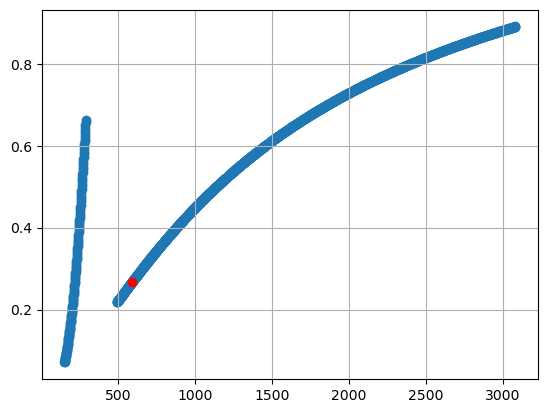

In [227]:
plt.scatter(combined_e[30][:-1],combined_cs2[30])
plt.scatter(combined_e[30][:-1][238],combined_cs2[30][238],color = 'red')
plt.grid()
plt.show()

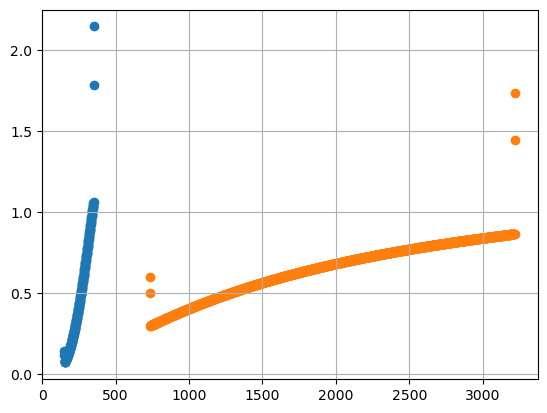

In [228]:
plt.scatter(e_curve_1,cs2_1)
plt.scatter(e_curve_2,cs2_2)
plt.grid()
plt.show()

In [229]:
mu_curve_1[-1]

1296.9110576675555

In [230]:
mu_curve_2[0]

1300.4653723564197

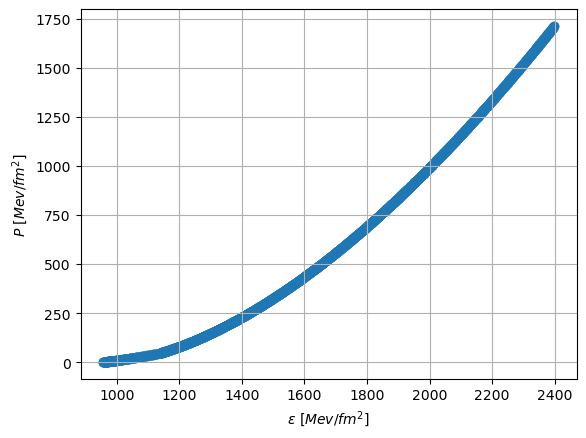

In [231]:
plt.scatter(mu_total[30],p_total[30]);
plt.grid()
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.show();

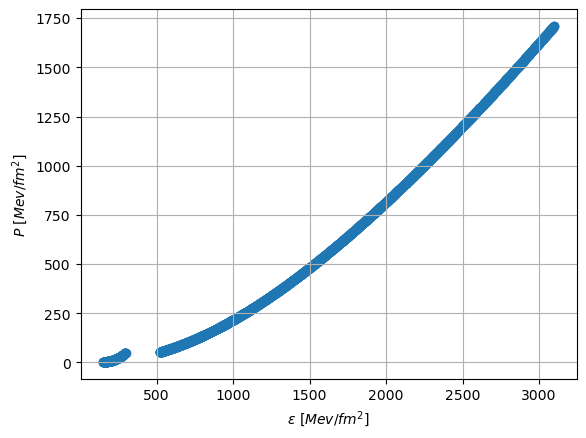

In [232]:
plt.scatter(combined_e[37],combined_p_1[37][:-1]);
plt.grid()
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.show();

In [233]:
e_total, p_total, mu_total, cs_total = combined_e, combined_p_1, combined_mu_1, combined_cs2

In [181]:
len(e_total[0])

1898

In [182]:
len(n_total_1[0])

1898

In [183]:
len(p_total[0])

1899

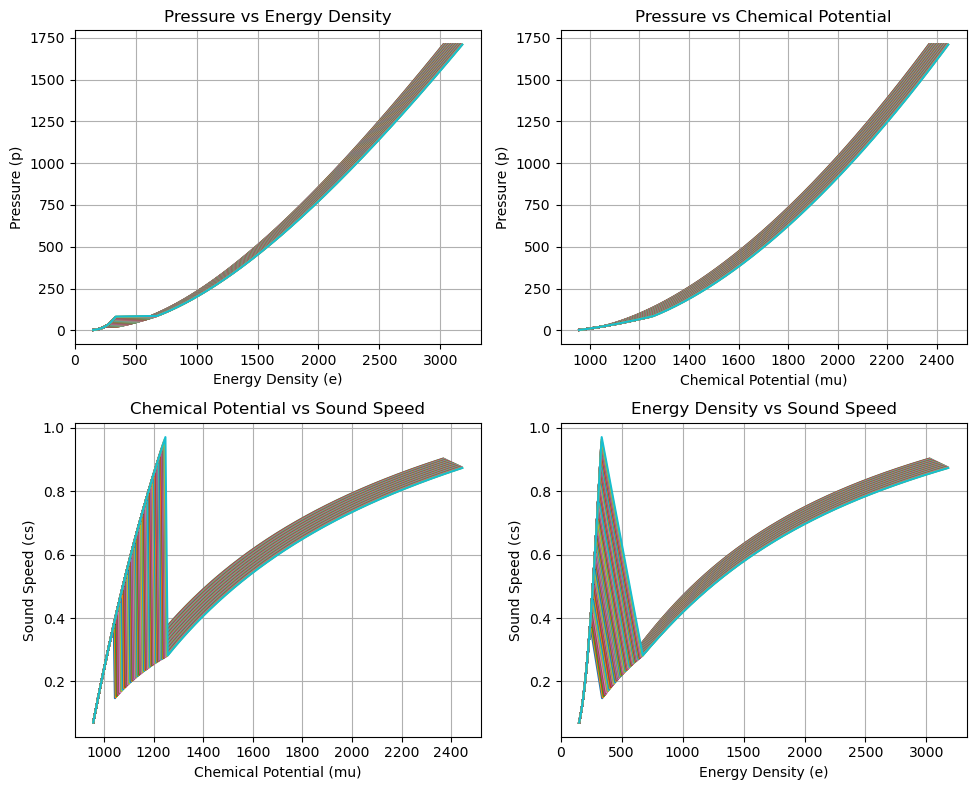

In [72]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for i in range(len(p_total)-20):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].plot(e_total[i], p_total[i][:-1])

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i][:-1], p_total[i][:-1])

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i][:-2], cs_total[i])

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i][:-1], cs_total[i])

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].grid(True)
#axes[0, 0].legend()

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)
#axes[0, 1].legend()

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)
#axes[1, 0].legend()

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].grid(True)
#axes[1, 1].legend()

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

In [73]:
delta_P_optimal_1 = []
b_optimal_1 = []
a_optimal_1 = []
P_optimal_1 = []
min_distance_points_1 = []
min_distances_1 = []

P_all_max = []
# Iterate through each mu_total and p_total index
for index in range(100):

    P_crit_1 = P_crit[index]*(1+0.01)
    P_crit_2 = P_crit[index]*(1+0.3)
    P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)
    delta_P = np.linspace(P_crit[index]*0.01,P_crit[index]*0.3,1000)
    
    delta_P_optimal = []
    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for i in range(len(P_crit_new)):
        P = P_crit_new[i]
        dp = delta_P[i]
        # Define your points
        x1, y1 = mu_total[index][0], p_total[index][0]  # First point the curve must pass through
        x2, y2 = mu_crit[index],P   # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[index][1:])  # Hadronic part x_values
        f_values = np.array(p_total[index][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return 0

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            delta_P_optimal.append(dp)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

        else:
            continue
    # Convert min_distances to a NumPy array
    a_optimal_1.append(a_optimal)
    b_optimal_1.append(b_optimal)
    P_optimal_1.append(P_optimal)
    delta_P_optimal_1.append(delta_P_optimal)
    min_distance_points_1.append(min_distance_points)
    min_distances_1.append(min_distances)

In [86]:
def find_first_larger_index(lst, value):
    return next((i for i, x in enumerate(lst) if x > value), None)

def gradient(n, m):
    
    if len(n) != len(m):
        raise ValueError("n and m must have the same length.")
    
    gradients = []
    for i in range(len(n) - 1):  # Loop up to the second-to-last element
        grad = (n[i + 1] - n[i]) / (m[i + 1] - m[i])
        gradients.append(grad)
    
    return gradients

def compute_n_e(P, mu):
    """Compute number density (n_quad) and energy density (e_quad) from pressure (P) and chemical potential (mu)."""
    n_quad = gradient(P, mu)
    e_quad = (n_quad * mu[:-1]) - P[:-1]
    cs_quad = gradient(P[:-1],e_quad)
    return n_quad, e_quad, cs_quad


from TOV_Solver import generate_mr_curve
from EOS_construction import constructing_EOS

In [98]:
import numpy as np

def concatenate_eos(P_max_points_1,mu_crit,P_all_1,p_total,mu_total,a_optimal_1,b_optimal_1,e_total,n_total):
    eos_final = []
    for i in range(len(mu_crit)-36):

        x2, y2 = mu_crit[i], P_all_1[i][0]  # Critical point
        a_op = a_optimal_1[i][0]
        b_op = b_optimal_1[i][0]        
        # Define quadratic function
        def quadratic(x):
            return a_op * (x - x2)**2 + b_op * (x - x2) + y2
        
        # Generate smooth quadratic fit until quark EOS
        index = find_first_larger_index(mu_total[i], P_max_points_1[i][0][0])
        mu_mixed = np.linspace(mu_total[i][0], mu_total[i][index], len(mu_total[i][:index]))
        p_fit = quadratic(mu_mixed)
        n_mix,e_mix,cs_mix = compute_n_e(p_fit, mu_mixed)
        
        e_t = np.concatenate((e_mix, e_total[i][index:]))
        cs_t = np.concatenate((cs_mix, cs_total[i][index:]))
        p_t = np.concatenate((p_fit, p_total[i][index:]))
        mu_t = np.concatenate((mu_mixed, mu_total[i][index:]))

        #n_mix,e_t,cs_t = compute_n_e(p_t, mu_t)
        eos_final.append((p_t, mu_t, e_t, cs_t))
    #print(index)
    #print(mu_mixed)
    #print(mu_total[i][index:])
    return eos_final

In [99]:
min_distance_points_1[0]

[(1212.707023234301, 107.38745269130418),
 (1213.2732641377631, 107.7618460777422),
 (1213.2732641377631, 107.7618460786854),
 (1213.8398990433552, 108.13702126860821),
 (1213.8398990433552, 108.13702126861408),
 (1214.4069276773032, 108.51297934832247),
 (1214.9743497664035, 108.88972013852069),
 (1214.9743497664035, 108.88971982116433),
 (1215.5421650380194, 109.26724472128558),
 (1215.5421650380194, 109.26724503961483),
 (1216.1103732200813, 109.64555387057291),
 (1216.1103732200813, 109.64555386964352),
 (1216.6789740410827, 110.0246474002771),
 (1217.2479672300797, 110.40452671595983),
 (1217.2479672300797, 110.40452671594964),
 (1217.8173525166885, 110.78519163439864),
 (1217.8173525166885, 110.78519163437973),
 (1218.387129631083, 111.16664324139407),
 (1218.387129631083, 111.16664324047183),
 (1218.9572983039943, 111.54888167055331),
 (1219.5278582667067, 111.93190737359313),
 (1219.5278582667067, 111.93190737358326),
 (1220.0988092510581, 112.31572143480801),
 (1220.0988092510

In [100]:
len(P_optimal_1)

100

In [101]:
P_optimal_1

[[23.703817970718134,
  23.70996000845213,
  23.71610204618612,
  23.722244083920113,
  23.728386121654108,
  23.734528159388102,
  23.740670197122096,
  23.746812234856087,
  23.75295427259008,
  23.759096310324075,
  23.76523834805807,
  23.771380385792064,
  23.777522423526058,
  23.78366446126005,
  23.789806498994043,
  23.795948536728037,
  23.80209057446203,
  23.808232612196022,
  23.814374649930016,
  23.82051668766401,
  23.826658725398005,
  23.832800763132,
  23.838942800865993,
  23.845084838599984,
  23.85122687633398,
  23.857368914067973,
  23.863510951801967,
  23.86965298953596,
  23.87579502726995,
  23.881937065003946,
  23.88807910273794,
  23.894221140471934,
  23.90036317820593,
  23.906505215939923,
  23.912647253673914,
  23.918789291407908,
  23.924931329141902,
  23.931073366875896,
  23.937215404609887,
  23.94335744234388,
  23.949499480077876,
  23.95564151781187,
  23.961783555545864,
  23.96792559327986,
  23.97406763101385,
  23.980209668747843,
  23.98

In [102]:
eos = concatenate_eos(min_distance_points_1,mu_crit,P_optimal_1,p_total,mu_total,a_optimal_1,b_optimal_1,e_total,n_total)

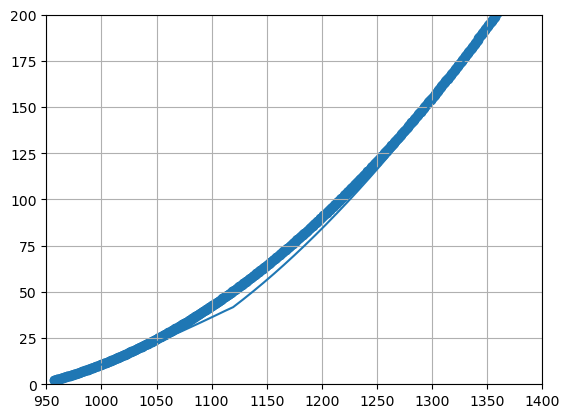

In [106]:
plt.scatter(eos[24][1],eos[24][0])
plt.plot(mu_total[24],p_total[24])
plt.xlim([950, 1400])
plt.ylim([0, 200])
plt.grid()

In [104]:
r2, m2, c2, l2 = [], [], [], []
r1, m1, c1, l1 = [], [], [], []

In [105]:
r2, m2, c2, l2 = generate_mr_curve(e_total[40], p_total[40])
r1, m1, c1, l1 = generate_mr_curve(eos[40][2], eos[40][0][:-1])

In [ ]:
len(e_to)

In [109]:
import numpy as np

# Initialize indices as None
i_c, i_c1 = None, None

# Iterate over the valid range
for i in range(len(eos)-1):
    # Check if cs_total[40][i] > 1 and store the first occurrence
    if cs_total[40][i] > 1 and i_c is None:
        i_c = int(i*(1/25))
    
    # Check if cs_quad_list[i] > 1 and store the first occurrence
    elif eos[40][3][i] > 1 and i_c1 is None:
        i_c1 = int(i*(1/25))

    # Exit loop early if both indices are found
    if i_c is not None and i_c1 is not None:
        break

print(f"i_c = {i_c}, i_c1 = {i_c1}")

i_c = None, i_c1 = None


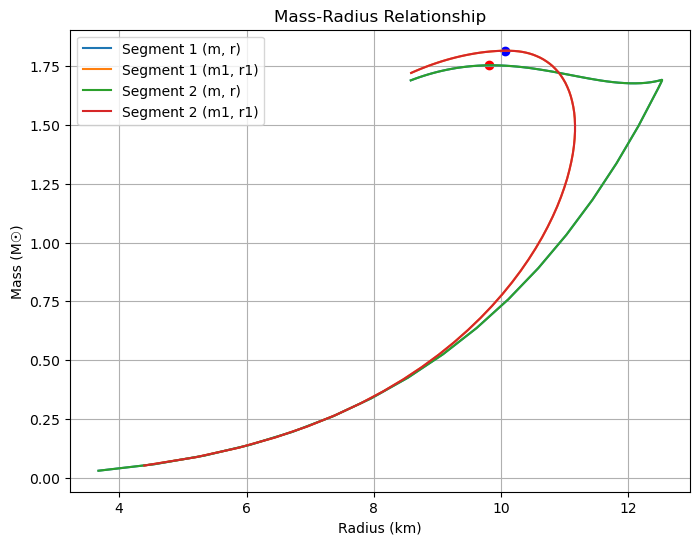

In [110]:
plt.figure(figsize=(8, 6))

# Plot the first and second segments for both sets
plt.plot(r2[:i_c], m2[:i_c], label="Segment 1 (m, r)")
plt.plot(r1[:i_c1], m1[:i_c1], label="Segment 1 (m1, r1)")
plt.plot(r2[i_c:], m2[i_c:], label="Segment 2 (m, r)")
plt.plot(r1[i_c1:], m1[i_c1:], label="Segment 2 (m1, r1)")
plt.scatter(r2[np.argmax(m2)], m2[np.argmax(m2)], color='red', marker='o')
plt.scatter(r1[np.argmax(m1)], m1[np.argmax(m1)], color='blue', marker='o')

# Labels and legend
plt.ylabel("Mass (M☉)")
plt.xlabel("Radius (km)")
plt.legend()
plt.title("Mass-Radius Relationship")
plt.grid(True)

plt.show()

In [111]:
from itertools import product
import numpy as np
@jit(nopython=True)
def quad_P(mu_c, mu, alpha, beta, delP, P_c):
    t1 = alpha*(mu - mu_c)**2
    t2 = beta*(mu - mu_c)
    t3 = (1+delP)*P_c
    re = t1 + t2 + t3
    return re

@jit(nopython=True)
def alpha(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        re = (t1 - t2)/(mu_c_q - mu_c_h)
    return re

@jit(nopython=True)
def beta(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        t3 = (P_q - P_h)/(mu_c_q - mu_c_h)
        re = t1 + t2 - t3
    return re

def find_valid_parameters(delta_P_arr, y_intersect, x_intersect, p_total, mu_total):
    A, B = [], []
    mu_c_h_arr, mu_c_q_arr = [], []
    P_c_h_arr, P_c_q_arr = [], []
    delta_P_found = []

    index = find_first_larger_index(p_total, y_intersect)
    #print(index)
    x1 = np.array(mu_total[:index])
    y1 = np.array(p_total[:index])

    x2 = np.array(mu_total[index:])
    y2 = np.array(p_total[index:])

    P_h_int_func = interpolate.interp1d(x1, y1, fill_value="extrapolate")
    P_q_int_func = interpolate.interp1d(x2, y2, fill_value="extrapolate")

    mu_new = np.linspace(1050, 1385, 1000)
    P_had_array = P_h_int_func(mu_new)
    P_quark_array = P_q_int_func(mu_new)
    #plt.plot(x1,y1)
    #plt.plot(x2,y2)
    #plt.show()
    #plt.plot(mu_new,P_had_array)
    #plt.plot(mu_new,P_quark_array)
    #plt.show()
    y_diff = np.abs(P_had_array - P_quark_array)

    for delta_P in delta_P_arr:
        found = False

        # Iterate through all combinations of mu_c_h and mu_c_q
        for mu_c_h, mu_c_q in product(mu_new, repeat=2):
            if found:
                break

            P_h = P_h_int_func(mu_c_h)
            P_q = P_q_int_func(mu_c_q)

            alp = alpha(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)
            bet = beta(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)

            # Check if alpha is positive
            if alp <= 0:
                continue

            # Calculate the mixed phase pressure
            P_m = quad_P(x_intersect, mu_new, alp, bet, delta_P, y_intersect)

            # Split the pressure difference calculation
            min_idx = np.argmin(y_diff)
            m_h_P_diff = P_m[:min_idx] - P_had_array[:min_idx]
            m_q_P_diff = P_m[min_idx:] - P_quark_array[min_idx:]

            # Validate the pressure conditions
            if np.all(m_h_P_diff >= 0) and np.all(m_q_P_diff >= 0):
                #print(np.min(m_h_P_diff), np.min(m_q_P_diff))
                delta_P_found.append(delta_P)
                A.append(alp)
                B.append(bet)
                mu_c_h_arr.append(mu_c_h)
                mu_c_q_arr.append(mu_c_q)
                P_c_h_arr.append(P_h)
                P_c_q_arr.append(P_q)
                found = True

    print(f"Found {len(A)} valid sets of parameters.")
    return A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, delta_P_found

In [112]:
delta_P_arr = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.10]

In [115]:
A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, delta_P_found = find_valid_parameters(delta_P_arr, P_crit[40], mu_crit[40], p_total[40], mu_total[40])

Found 10 valid sets of parameters.


In [235]:
def mixed_phase(mu_total, p_total,n_total, A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, mu_crit, P_crit):
    P_arr_dp = []
    E_arr_dp = []
    number_density_dp = []
    mu_arr_dp = []

    for i in range(len(A)):
        index_1 = find_first_larger_index(mu_total, mu_c_h_arr[i])
        index_2 = find_first_larger_index(mu_total, mu_c_q_arr[i])

        mu_mixed = np.linspace(mu_total[index_1], mu_total[index_2], len(mu_total[index_1:index_2]))

        P_m = quad_P(mu_crit, mu_mixed, A[i], B[i], delta_P_arr[i], P_crit)
        P_had_half = p_total[:index_1]
        P_quark_half = p_total[index_2:]

        grad_had = n_total[:index_1]
        grad_m = gradient(P_m,mu_mixed)
        grad_quark = n_total[index_2:]

        mu_arr = np.concatenate((mu_total[:index_1], mu_mixed[:-1], mu_total[index_2:]))

        grad_dummy = np.concatenate((grad_had,grad_m,grad_quark))
        P_arr_dummy = np.concatenate((P_had_half,P_m[:-1],P_quark_half))
        e_dummy = (grad_dummy*mu_arr)-P_arr_dummy

        P_arr_dp.append(P_arr_dummy)
        E_arr_dp.append(e_dummy)
        number_density_dp.append(grad_dummy)
        mu_arr_dp.append(mu_arr)

    return P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp

In [236]:
P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp = mixed_phase(mu_total[40], p_total[40], n_total_1[40], A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, mu_crit[40], P_crit[40])

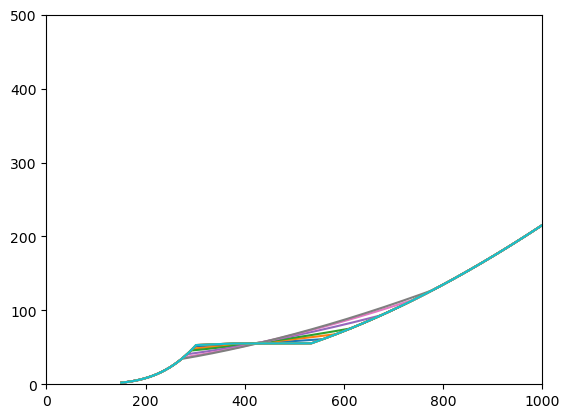

In [237]:
for i in range(10):
    plt.plot(E_arr_dp[i],P_arr_dp[i])
plt.xlim(0,1000)
plt.ylim(0,500)
plt.show()

In [238]:
radii, masses, compacts, love_nums = [0]*len(delta_P_arr), [0]*len(delta_P_arr), [0]*len(delta_P_arr), [0]*len(delta_P_arr)

In [239]:
for i in range(10):
    radii[i], masses[i], compacts[i], love_nums[i] = generate_mr_curve(E_arr_dp[i], P_arr_dp[i])

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


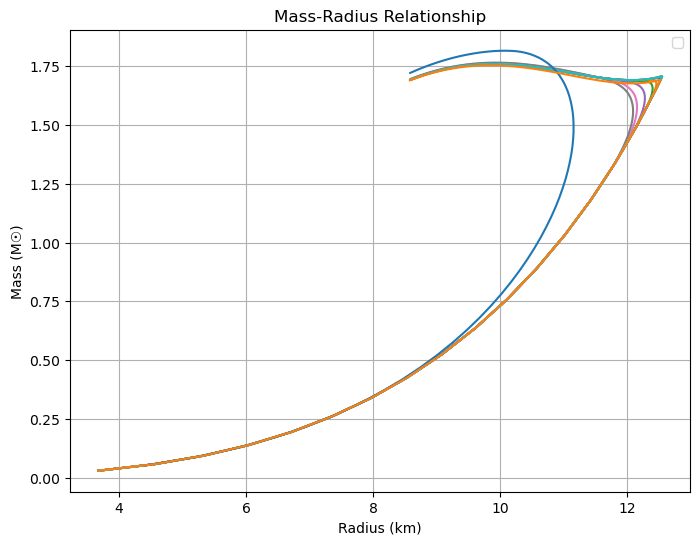

In [240]:
plt.figure(figsize=(8, 6))

for i in range(10):
    plt.plot(radii[i], masses[i])
plt.plot(r1, m1)
plt.plot(r2,m2)

# Labels and legend
plt.ylabel("Mass (M☉)")
plt.xlabel("Radius (km)")
plt.legend()
plt.title("Mass-Radius Relationship")
plt.grid(True)

plt.show()

In [241]:
def check_twins(mass):
    for i in range(len(mass)-2):
        if mass[i+1]-mass[i] < 0 and mass[i+2]-mass[i+1] > 0:
            return print('True')
    else:
        return print('False')

In [242]:
A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, delta_P_found = [0]*10, [0]*10, [0]*10, [0]*10, [0]*10, [0]*10, [0]*10

for i in range(10):
    j = ((i*10)-1)//2
    A[i], B[i], mu_c_h_arr[i], mu_c_q_arr[i], P_c_h_arr[i], P_c_q_arr[i], delta_P_found[i] = find_valid_parameters(delta_P_arr, P_crit[j], mu_crit[j], p_total[j], mu_total[j])

Found 10 valid sets of parameters.
Found 10 valid sets of parameters.
Found 8 valid sets of parameters.
Found 8 valid sets of parameters.
Found 10 valid sets of parameters.
Found 10 valid sets of parameters.
Found 8 valid sets of parameters.
Found 10 valid sets of parameters.
Found 8 valid sets of parameters.
Found 10 valid sets of parameters.


In [248]:
j_list = []
for i in range(10):
    j = ((i*10)-1)//2
    j_list.append(j)

In [251]:
len(j_list)

10

In [254]:
for i in range(9):

    j = j_list[i+1]
    P_arr_dp[i], E_arr_dp[i], number_density_dp[i], mu_arr_dp[i] = mixed_phase(mu_total[j], p_total[j], n_total_1[j], A[i], B[i], mu_c_h_arr[i], mu_c_q_arr[i], P_c_h_arr[i], P_c_q_arr[i], mu_crit[j], P_crit[j])
    print(i)

0
1
2
3
4
5
6
7
8


In [256]:
radii_1, masses_1, compacts_1, love_nums_1 = [], [], [], []
for i in range(9):
    radii, masses, compacts, love_nums = [0]*len(delta_P_found[i]), [0]*len(delta_P_found[i]), [0]*len(delta_P_found[i]), [0]*len(delta_P_found[i])
    for j in range(len(delta_P_found[i])):
        radii[j], masses[j], compacts[j], love_nums[j] = generate_mr_curve(E_arr_dp[i][j], P_arr_dp[i][j])
    radii_1.append(radii)
    masses_1.append(masses)
    compacts_1.append(compacts)
    love_nums_1.append(love_nums)

/Users/apple/Downloads/Thesis/Phase_Transition/code/Relation_Codes/TOV_Solver.py:49: RuntimeWarning: invalid value encountered in scalar divide
  k2 = 8 / 5 * C**5 * denom**2 * (2 + 2 * C * (y - 1) - y) / (


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


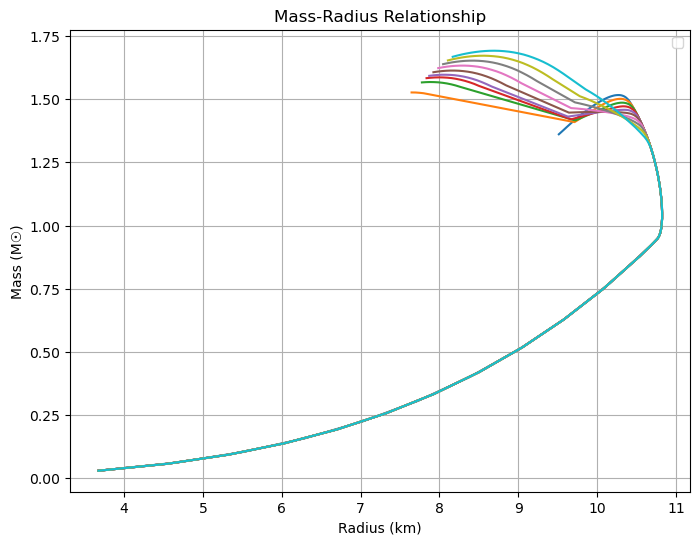

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


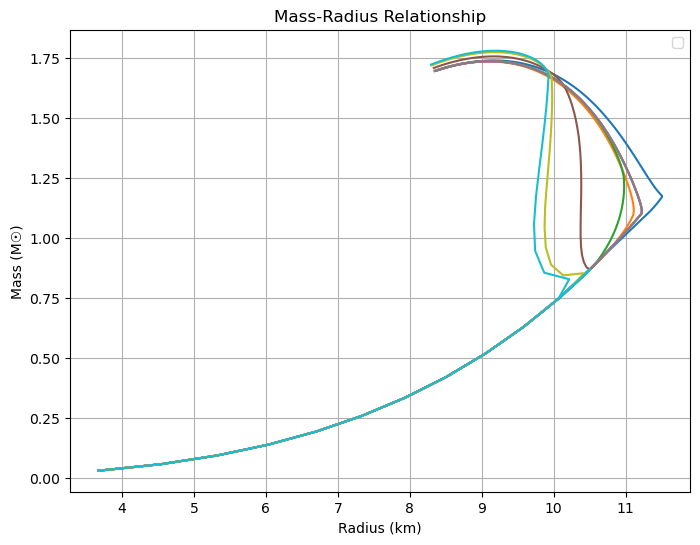

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


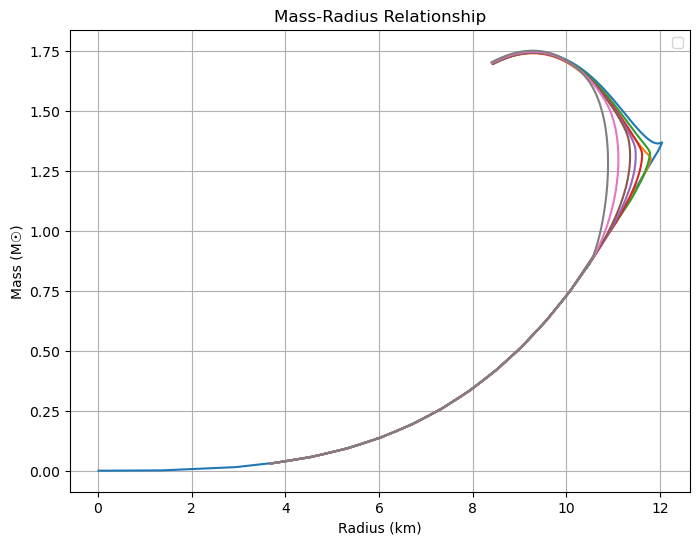

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


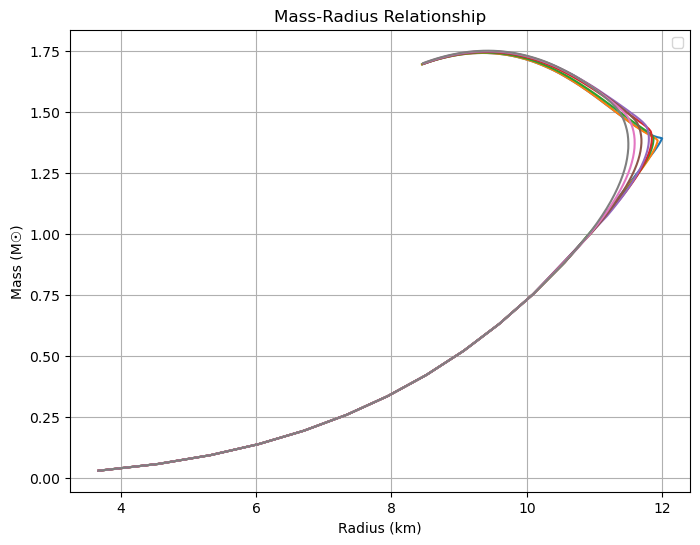

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


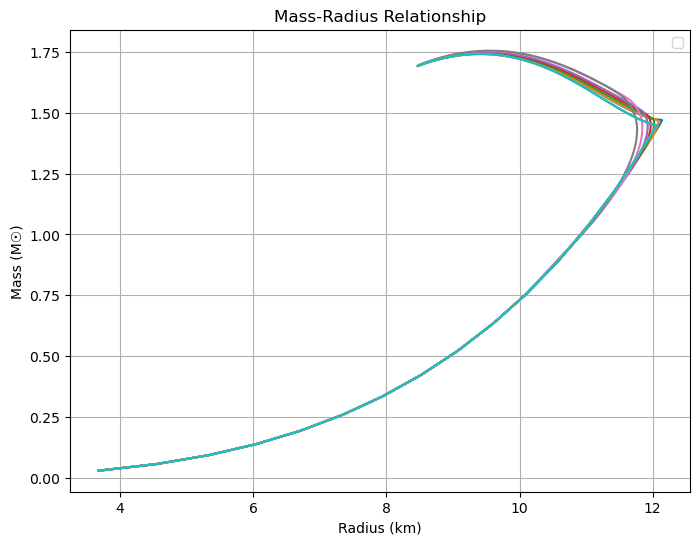

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


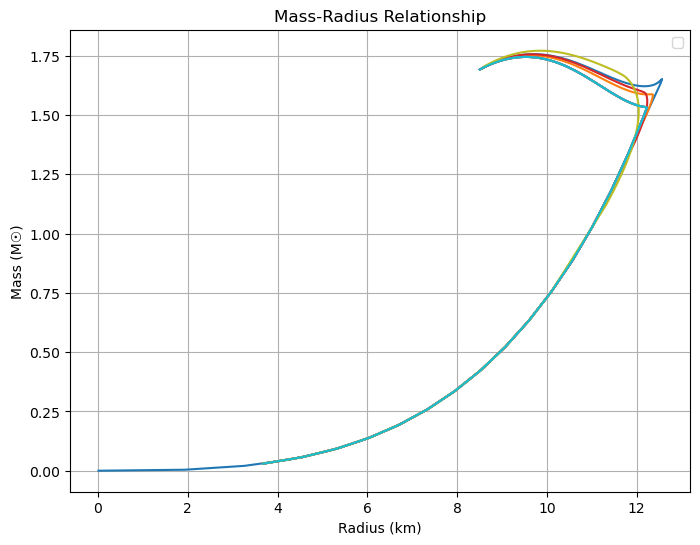

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


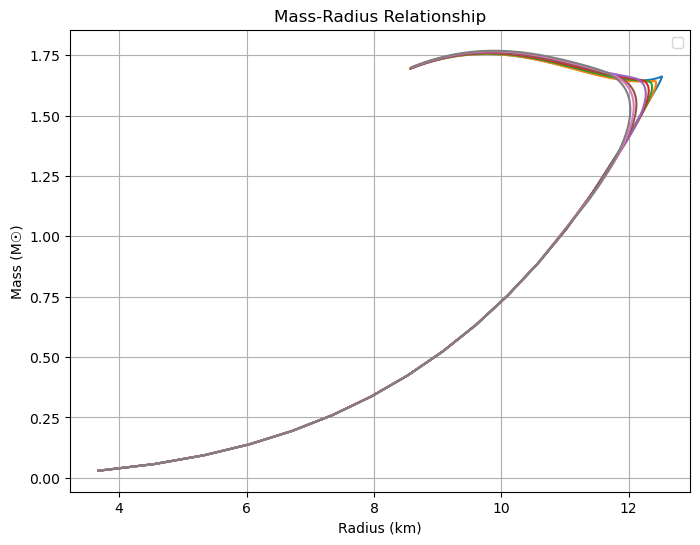

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


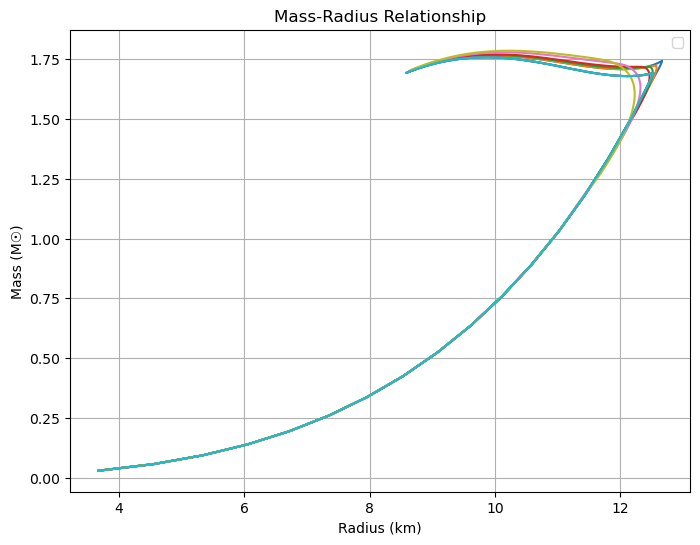

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


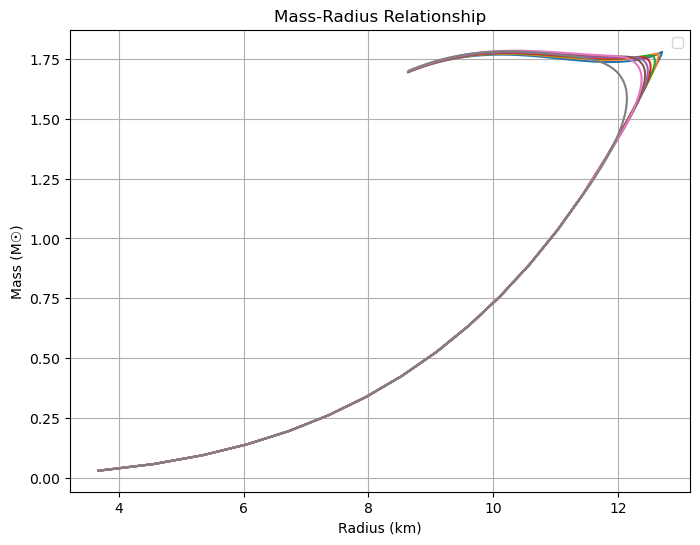

In [257]:
for j in range(9):
    plt.figure(figsize=(8, 6))

    for i in range(len(radii_1[j])):
        plt.plot(radii_1[j][i], masses_1[j][i])
    #plt.plot(r1, m1)
    #plt.plot(r2,m2)

    # Labels and legend
    plt.ylabel("Mass (M☉)")
    plt.xlabel("Radius (km)")
    plt.legend()
    plt.title("Mass-Radius Relationship")
    plt.grid(True)

    plt.show()

False
0.01
True
0.02
True
0.03
True
0.04
True
0.05
True
0.06
False
0.07
False
0.08
False
0.09
False
0.1


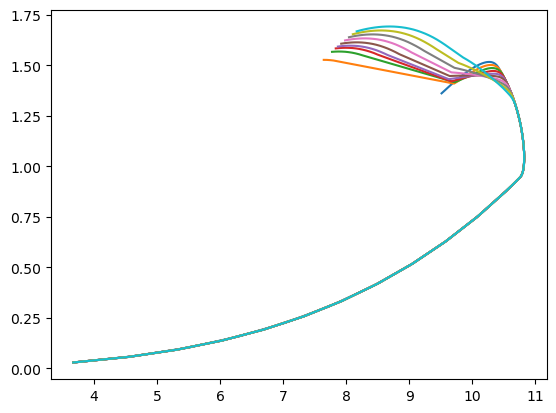

In [282]:
n = 0
#plt.figure(figsize=(10, 8))
for i in range(len(masses_1[n])):
    check_twins(masses_1[n][i])
    print(delta_P_found[n][i])
    plt.plot(radii_1[n][i], masses_1[n][i])
#plt.show()

In [272]:
mu_crit_twins =[]
for i in range(10):
    j = ((i*10)-1)//2
    mu_crit_twins.append(mu_crit[j])

In [286]:
list = [0,0, 0.01, 0, 0, 0.02, 0.02, 0.06, 0.06]

Text(0, 0.5, '$\\Delta_p$')

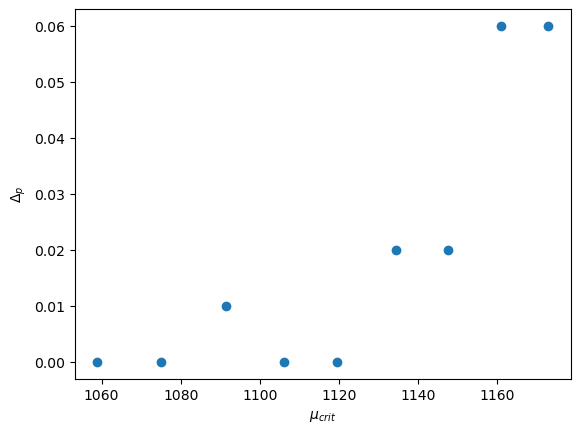

In [288]:
plt.scatter(mu_crit_twins[1:], list)
plt.xlabel(r"$\mu_{crit}$")
plt.ylabel(r"$\Delta_p$")

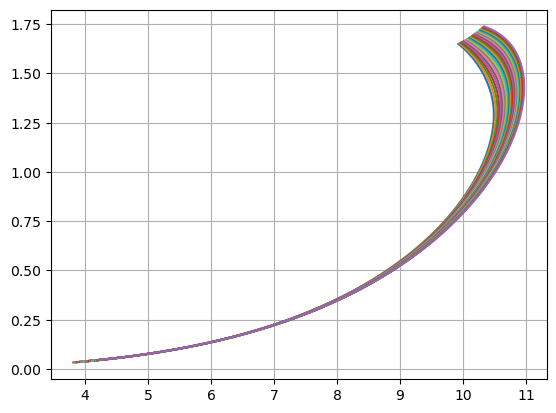

In [294]:
for i in range(25):
    plt.plot(radii[i],masses[i])
plt.grid()

ValueError: x and y must have same first dimension, but have shapes (1701,) and (1699,)

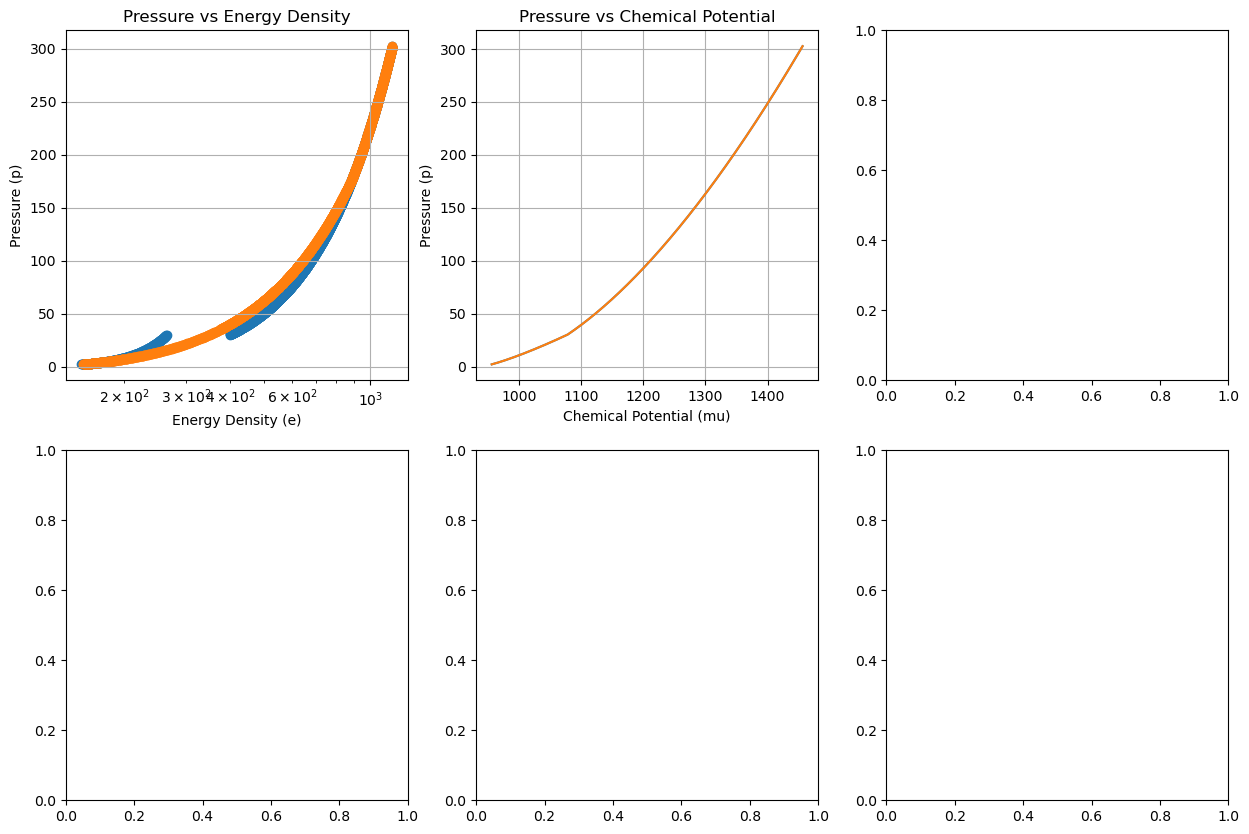

In [340]:
import matplotlib.pyplot as plt

def plot_eos(i, e_total, p_total, mu_total, cs_total, radii_1, masses_1):
    """
    Plots various properties of the Equation of State (EOS) for a given index.

    Parameters:
    - i: int, index of the EOS to plot
    - e_total: list of energy density values for different EOSs
    - p_total: list of pressure values for different EOSs
    - mu_total: list of chemical potential values for different EOSs
    - cs_total: list of sound speed values for different EOSs
    - generate_mr_curve: function that generates mass-radius data for an EOS
    """

    # Create a 2x3 grid of subplots
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    # Plot 1: Pressure vs Energy Density
    axes[0, 0].scatter(e_total[i], p_total[i][:-1])
    axes[0, 0].scatter(e_quad_list[i], eos[i][0][:-1])
    axes[0, 0].set_title('Pressure vs Energy Density')
    axes[0, 0].set_xlabel('Energy Density (e)')
    axes[0, 0].set_ylabel('Pressure (p)')
    axes[0, 0].set_xscale('log')
    axes[0, 0].grid(True)

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i], p_total[i])
    axes[0, 1].plot(eos[i][1], p_total[i])
    axes[0, 1].set_title('Pressure vs Chemical Potential')
    axes[0, 1].set_xlabel('Chemical Potential (mu)')
    axes[0, 1].set_ylabel('Pressure (p)')
    axes[0, 1].grid(True)

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i], cs_total[i])
    axes[1, 0].set_title('Chemical Potential vs Sound Speed')
    axes[1, 0].set_ylabel('Sound Speed (cs)')
    axes[1, 0].set_xlabel('Chemical Potential (mu)')
    axes[1, 0].grid(True)

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i], cs_total[i])
    axes[1, 1].set_title('Energy Density vs Sound Speed')
    axes[1, 1].set_ylabel('Sound Speed (cs)')
    axes[1, 1].set_xlabel('Energy Density (e)')
    axes[1, 1].set_xscale('log')
    axes[1, 1].grid(True)

    # Plot 5: Mass-Radius (M-R) Curve
    radii_111, masses_111, _, _ = generate_mr_curve(e_total[i], p_total[i])
    radii_112, masses_112, _, _ = generate_mr_curve(e_quad_list[i], p_total[i])
    axes[0, 2].plot(radii_111, masses_111, label=f'EOS {i+1}')
    axes[0, 2].plot(radii_112, masses_112, label=f'EOS {i+1}')
    axes[0, 2].set_title('Mass-Radius Curve')
    axes[0, 2].set_xlabel('Radius (km)')
    axes[0, 2].set_ylabel('Mass (M_sun)')
    axes[0, 2].legend()
    axes[0, 2].grid(True)

    # Adjust layout and show the plot
    plt.suptitle(f'Equation of State {i+1}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


plot_eos(i=10, e_total=e_total, p_total=p_total, mu_total=mu_total, cs_total=cs_total, radii_1=radii_1, masses_1=masses_1)

In [211]:
Del_p = [P_optimal_1[i][0] / P_crit[i] for i in range(len(P_optimal_1))]

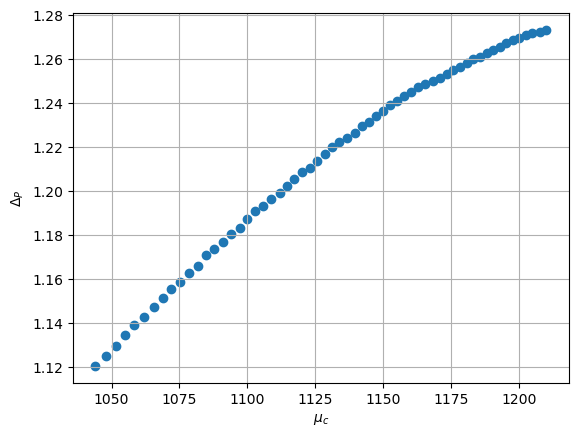

In [213]:
plt.scatter(mu_crit[:60],Del_p[:60]);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$\Delta_{P} $');
plt.show();

# Part 1, Relation of Maximum Interpolation

In [25]:
# Lists to store results
P_all = []
P_all_1 = []
P_max_points = []
P_max_points_1 = []
delta_P_Points = []
delta_P_optimal_max = []
P_all_max = []

# Store first values of a_opt and b_opt
a_opt_first_values = []
b_opt_first_values = []

# Iterate through each mu_total and p_total index
for index in range(100):

    P_crit_1 = P_crit[index] * (1 + 0.01)
    P_crit_2 = P_crit[index] * (1 + 0.3)
    P_crit_new = np.linspace(P_crit_1, P_crit_2, 1000)
    delta_P = np.linspace(P_crit[index] * 0.01, P_crit[index] * 0.3, 1000)
    
    delta_P_optimal = []
    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for i in range(len(P_crit_new)):
        P = P_crit_new[i]
        dp = delta_P[i]
        # Define your points
        x1, y1 = mu_total[index][0], p_total[index][0]  # First point the curve must pass through
        x2, y2 = mu_crit[index], P   # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[index][1:])  # Hadronic part x_values
        f_values = np.array(p_total[index][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return 0

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            delta_P_optimal.append(dp)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

        else:
            continue

    # Convert min_distances to a NumPy array
    min_distances = np.array(min_distances)
    P_optimal = np.array(P_optimal)
    delta_P_optimal = np.array(delta_P_optimal)
    min_distance_points = np.array(min_distance_points)

    # Check if min_distances and P_optimal contain values
    if min_distances.size > 0 and P_optimal.size > 0 and min_distance_points.size > 0:
        # Find the index of the minimum distance across all runs
        index_min = min_distances.argmin()

        # Save a specific optimal value to P_all based on index
        P_all.append(P_optimal[index_min])
        P_all_1.append(P_optimal[0])

        P_max_points.append(min_distance_points[index_min])
        P_max_points_1.append(min_distance_points[0])
        delta_P_Points.append(delta_P_optimal[0])
        delta_P_optimal_max.append(delta_P_optimal[-1])
        P_all_max.append(P_optimal[-1])

        # Save the first values of a_opt and b_opt
        a_opt_first_values.append(a_optimal[0])
        b_opt_first_values.append(b_optimal[0])
    else:
        # Append zeros if arrays are empty
        P_all.append(0)
        P_all_1.append(0)
        P_max_points.append(0)
        P_max_points_1.append(0)
        a_opt_first_values.append(0)
        b_opt_first_values.append(0)

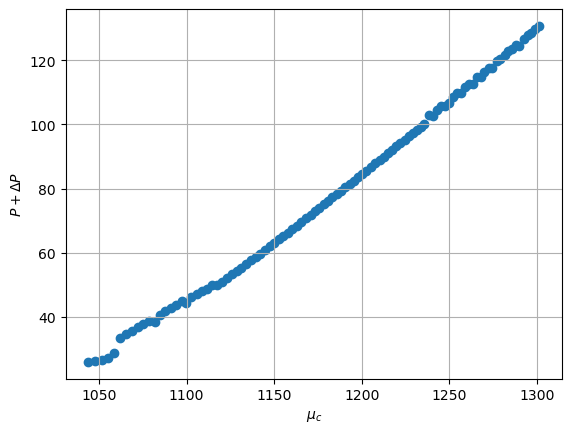

In [26]:
plt.scatter(mu_crit,P_all);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$P + \Delta P $');
plt.show();

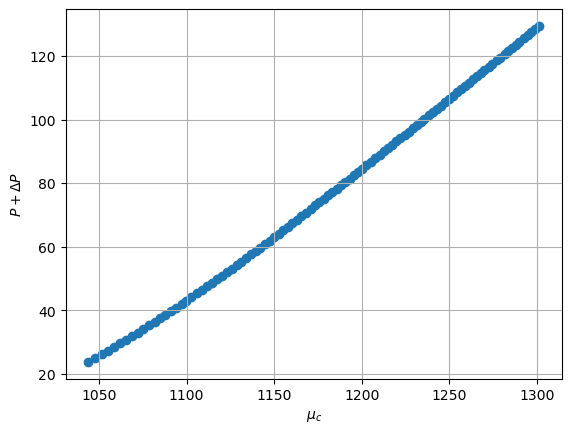

In [27]:
plt.scatter(mu_crit,P_all_1);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$P + \Delta P $');
plt.show();

In [29]:
del_p = np.array(delta_P_Points)/np.array(P_crit)

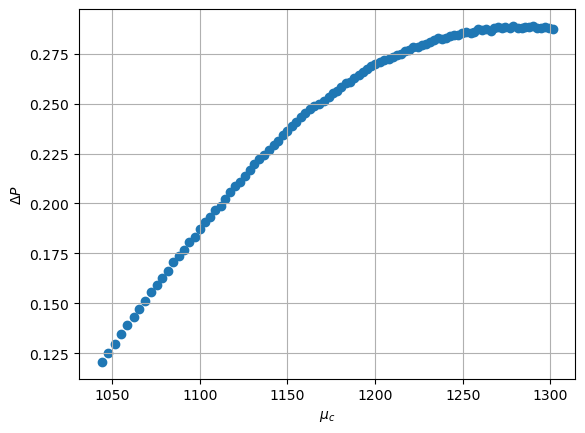

In [30]:
plt.scatter(mu_crit,del_p);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$\Delta P $');
plt.show();

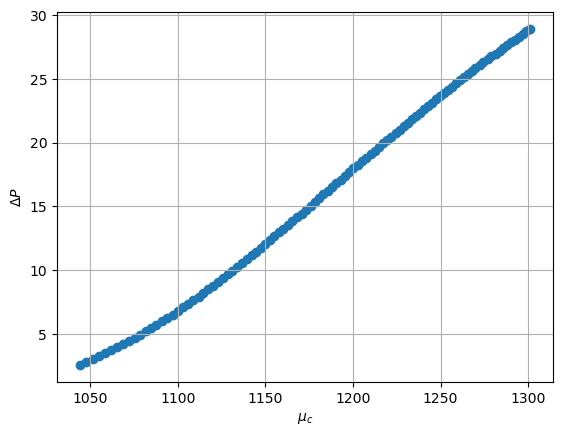

In [65]:
plt.scatter(mu_crit,delta_P_Points);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$\Delta P $');
plt.show();

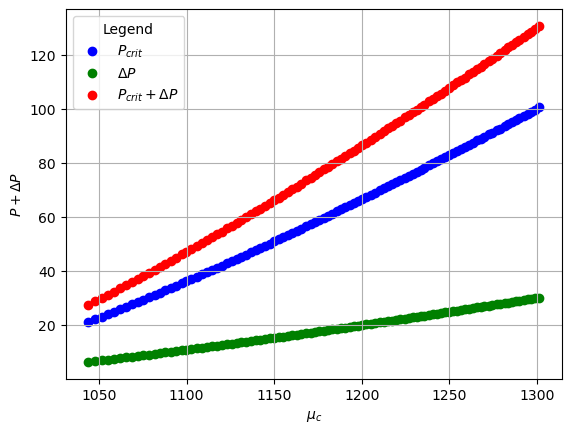

In [66]:
# Plotting the scatter points
plt.scatter(mu_crit, P_crit, label=r"$P_{crit}$", color='b')
plt.scatter(mu_crit, delta_P_optimal_max, label=r"$\Delta P$", color='g')
plt.scatter(mu_crit, P_all_max, label=r"$P_{crit} + \Delta P$", color='r')

# Adding grid, labels, and legend
plt.grid()
plt.xlabel(r'$\mu_c$')
plt.ylabel(r'$P + \Delta P$')

# Display the legend to label the lines
plt.legend(title='Legend', loc='best')

# Show the plot
plt.show()


In [67]:
len(delta_P_optimal_max)

100

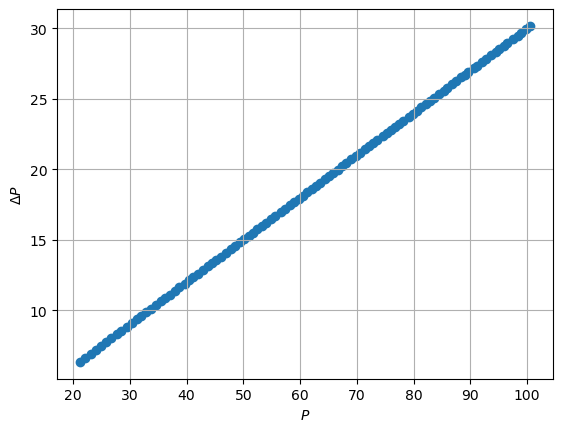

In [68]:
plt.scatter(P_crit,delta_P_optimal_max);
plt.grid();
plt.xlabel(r'$P$');
plt.ylabel(r'$\Delta P $');
plt.show();

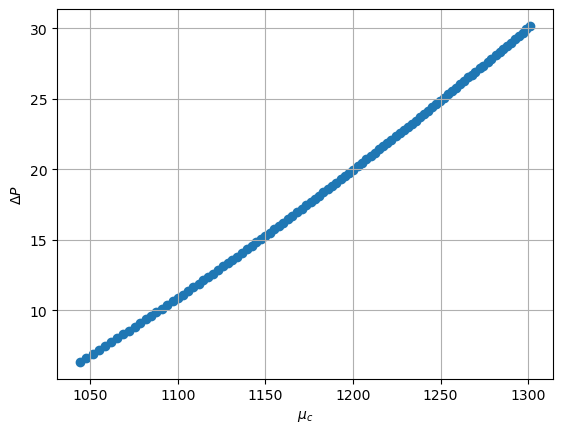

In [69]:
plt.scatter(mu_crit,delta_P_optimal_max);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$\Delta P $');
plt.show();

 Curve Fit

In [ ]:
import pandas as pd

# Create a DataFrame
df = pd.DataFrame({'Column1': list1, 'Column2': list2, 'Column3': list3})

# Save to Excel
df.to_excel("output.xlsx", index=False)